In [19]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay,
    PrecisionRecallDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [10]:
df = pd.read_csv(r"D:\Download\Churn_Modelling.csv")

print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:\n", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nStatistical summary:")
display(df.describe())
print("\nTarget distribution:\n", df["Exited"].value_counts())
print("\nTarget percentages:\n", (df["Exited"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



Columns:
 ['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Data types:
 RowNumber            int64
CustomerId           int64
Surname             object
CreditScore          int64
Geography           object
Gender              object
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

Missing values:
 RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Duplicate rows: 0

Statistical summary:


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Target distribution:
 Exited
0    7963
1    2037
Name: count, dtype: int64

Target percentages:
 Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


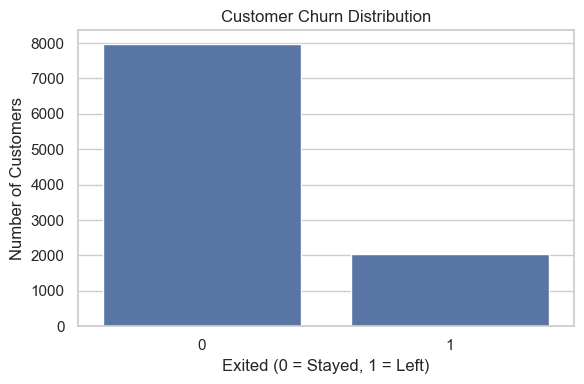

In [11]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Exited")
plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

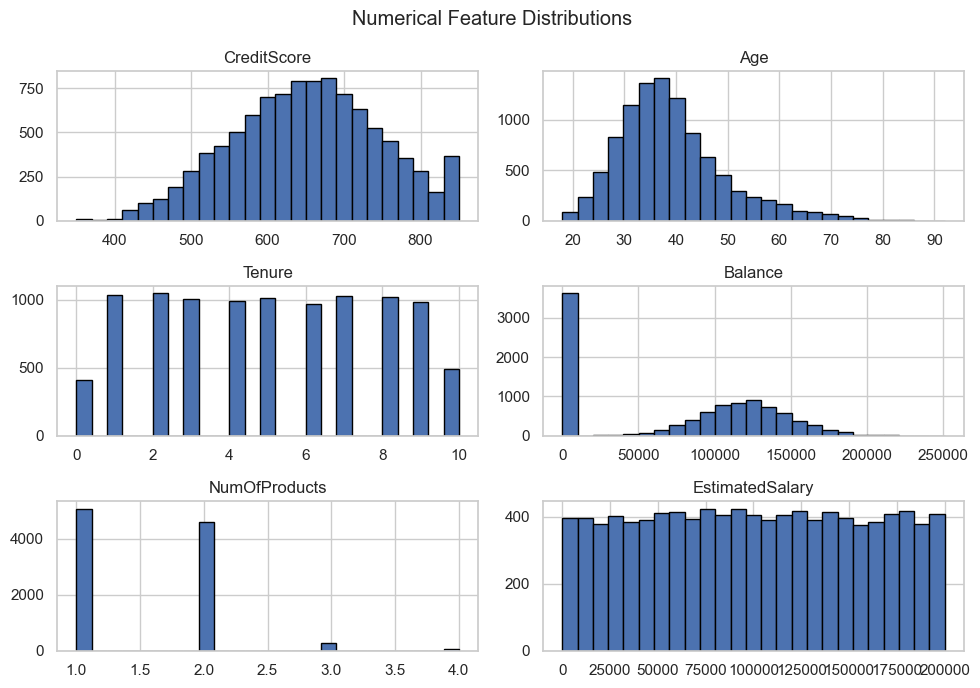

In [14]:
numerical_eda_cols = [
    "CreditScore", "Age", "Tenure",
    "Balance", "NumOfProducts", "EstimatedSalary"
]

df[numerical_eda_cols].hist(
    figsize=(10, 7), bins=25, edgecolor="black"
)
plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

In [17]:
df_model = df.drop(
    columns=["RowNumber", "CustomerId", "Surname"],
    errors="ignore"
)
X = df_model.drop(columns=["Exited"])
y = df_model["Exited"]
categorical_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()
numerical_cols = X.select_dtypes(
    include=["number"]
).columns.tolist()
print("Categorical features:", categorical_cols)
print("Numerical features:", numerical_cols)

Categorical features: ['Geography', 'Gender']
Numerical features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


In [20]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

print("Preprocessing pipelines created.")

Preprocessing pipelines created.


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (8000, 10)
Testing set: (2000, 10)


In [22]:
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        max_iter=20000
    ))
])

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)
baseline_scores = baseline_model.decision_function(X_test)

print("Baseline Linear SVM trained.")

Baseline Linear SVM trained.


In [23]:
def evaluate_model(name, y_true, predictions, scores):
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, scores)
    }

    print(f"\n{name}")
    for metric, value in results.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_true, predictions, zero_division=0))

    return results


baseline_results = evaluate_model(
    "Baseline Linear SVM",
    y_test, baseline_predictions, baseline_scores
)


Baseline Linear SVM
Accuracy: 0.7155
Precision: 0.3890
Recall: 0.6978
F1 Score: 0.4996
ROC-AUC: 0.7769

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.70      0.50       407

    accuracy                           0.72      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.72      0.74      2000



In [24]:
parameter_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

cross_validation = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

grid_search = GridSearchCV(
    estimator=baseline_model,
    param_grid=parameter_grid,
    scoring="f1",
    cv=cross_validation,
    n_jobs=-1,
    refit=True
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1:", round(grid_search.best_score_, 4))

Best parameters: {'classifier__C': 0.1}
Best cross-validation F1: 0.4899


In [25]:
tuned_predictions = best_model.predict(X_test)
tuned_scores = best_model.decision_function(X_test)

tuned_results = evaluate_model(
    "Tuned Linear SVM",
    y_test, tuned_predictions, tuned_scores
)


Tuned Linear SVM
Accuracy: 0.7150
Precision: 0.3885
Recall: 0.6978
F1 Score: 0.4991
ROC-AUC: 0.7770

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000



,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Baseline Linear SVM,0.7155,0.3890,0.6978,0.4996,0.7769
Tuned Linear SVM,0.7150,0.3885,0.6978,0.4991,0.7770


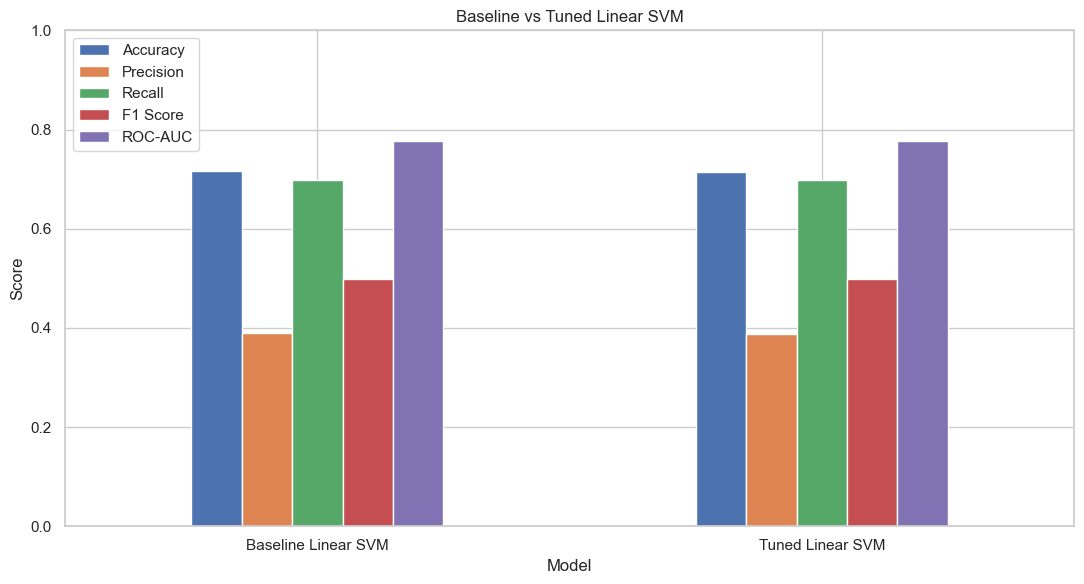

In [26]:
comparison = pd.DataFrame(
    [baseline_results, tuned_results]
).set_index("Model")

display(comparison.round(4))

comparison.plot(kind="bar", figsize=(11, 6))
plt.title("Baseline vs Tuned Linear SVM")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

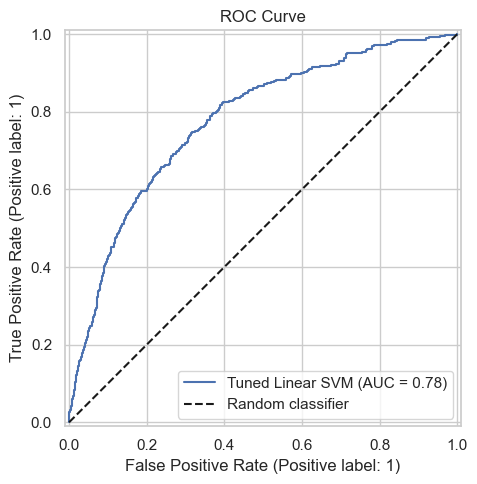

In [27]:
RocCurveDisplay.from_predictions(
    y_test, tuned_scores, name="Tuned Linear SVM"
)

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

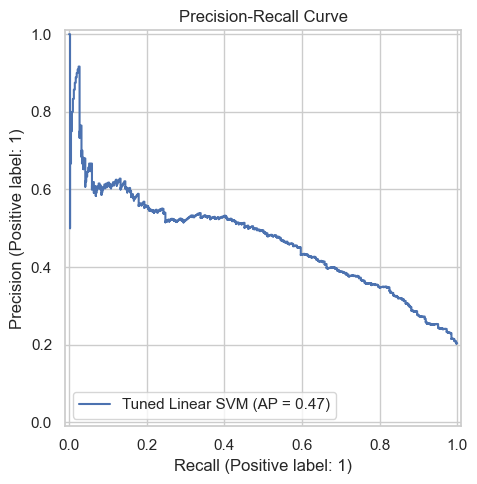

In [28]:
PrecisionRecallDisplay.from_predictions(
    y_test, tuned_scores, name="Tuned Linear SVM"
)

plt.title("Precision-Recall Curve")
plt.tight_layout()
plt.show()

,Feature,Coefficient,AbsoluteCoefficient
8,cat__Geography_Germany,0.340354,0.340354
1,num__Age,0.327391,0.327391
10,cat__Gender_Male,-0.222561,0.222561
6,num__IsActiveMember,-0.182842,0.182842
3,num__Balance,0.071210,0.071210
0,num__CreditScore,-0.034896,0.034896
9,cat__Geography_Spain,0.024394,0.024394
4,num__NumOfProducts,-0.023663,0.023663
7,num__EstimatedSalary,0.020897,0.020897
5,num__HasCrCard,-0.012233,0.012233


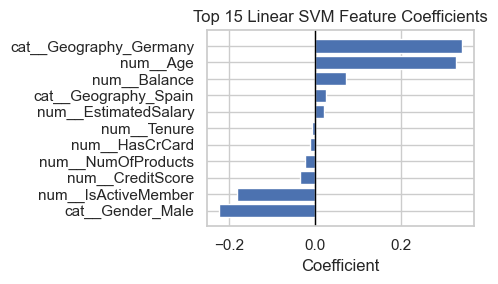

In [30]:
fitted_preprocessor = best_model.named_steps["preprocessor"]
linear_svm = best_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = linear_svm.coef_[0]

coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coefficient_df["AbsoluteCoefficient"] = coefficient_df["Coefficient"].abs()
coefficient_df = coefficient_df.sort_values(
    "AbsoluteCoefficient", ascending=False
)

display(coefficient_df.head(15))

top_features = coefficient_df.head(15).sort_values("Coefficient")

plt.figure(figsize=(5, 3))
plt.barh(top_features["Feature"], top_features["Coefficient"])
plt.axvline(0, color="black", linewidth=1)
plt.title("Top 15 Linear SVM Feature Coefficients")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()